# Практична робота: Використання понять теорії ймовірностей у теорії оптимального керування
Цей блокнот містить розв'язання задач зі статистики та аналізу даних за допомогою бібліотек Python (NumPy, SciPy, Matplotlib, Seaborn).

In [6]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Забезпечення відтворюваності випадкових результатів
np.random.seed(42)

### Завдання 1: Описова статистика
Згенерувати випадкову вибірку випадкових величин, об'ємом 100 елементів (цілі числа). Використовуючи бібліотеку NumPy, обчислити середнє значення, медіану, моду, дисперсію та стандартне відхилення.

In [7]:
data_1 = np.random.randint(1, 101, size=100)

mean_val = np.mean(data_1)
median_val = np.median(data_1)
mode_res = stats.mode(data_1, keepdims=True)
variance_val = np.var(data_1, ddof=1)
std_dev_val = np.std(data_1, ddof=1)

print(f"Згенеровані дані (перші 10): {data_1[:10]}...")
print(f"Середнє значення: {mean_val}")
print(f"Медіана: {median_val}")
print(f"Мода: {mode_res.mode[0]} (зустрічається {mode_res.count[0]} разів)")
print(f"Дисперсія: {variance_val}")
print(f"Стандартне відхилення: {std_dev_val}")

Згенеровані дані (перші 10): [52 93 15 72 61 21 83 87 75 75]...
Середнє значення: 51.54
Медіана: 54.0
Мода: 62 (зустрічається 5 разів)
Дисперсія: 865.8872727272727
Стандартне відхилення: 29.425962562459578


### Завдання 2: Тестування статистичних гіпотез (t-тест для однієї вибірки)
Згенерувати випадкову вибірку випадкових величин, об'ємом 50 елементів (дробові числа, які містять один знак після коми). Виконати t-тест для перевірки середнього значення вибірки.

In [8]:
data_2 = np.round(np.random.uniform(10.0, 30.0, size=50), 1)
hypothesized_mean = 20.0
t_stat, p_value = stats.ttest_1samp(data_2, hypothesized_mean)

print(f"Вибірка (перші 10): {data_2[:10]}")
print(f"T-статистика: {t_stat}, Р-значення: {p_value}")

alpha = 0.05
if p_value > alpha:
    print("Пояснення: Р-значення більше за рівень значущості (0.05). Немає підстав відхиляти нульову гіпотезу. Середнє значення вибірки statistically рівне 20.0.")
else:
    print("Пояснення: Р-значення менше або дорівнює рівню значущості (0.05). Нульова гіпотеза відхиляється.")

Вибірка (перші 10): [17.1 15.6 20.9 12.8 26.  11.5 29.7 25.4 14.  10.1]
T-статистика: -0.9760616035694809, Р-значення: 0.3338282635318084
Пояснення: Р-значення більше за рівень значущості (0.05). Немає підстав відхиляти нульову гіпотезу. Середнє значення вибірки statistically рівне 20.0.


### Завдання 3: Кореляція та регресія
Згенерувати дві випадкові вибірки випадкових величин, об'ємом 20 елементів (цілі числа). Обчислити коефіцієнт кореляції між двома наборами даних (кореляція Пірсона, кореляція Спірмана).

In [9]:
x_data = np.random.randint(1, 50, size=20)
y_data = x_data * 2 + np.random.randint(-5, 6, size=20)

pearson_corr, p_pearson = stats.pearsonr(x_data, y_data)
spearman_corr, p_spearman = stats.spearmanr(x_data, y_data)

print(f"X: {x_data}")
print(f"Y: {y_data}")
print(f"Кореляція Пірсона: {pearson_corr:.4f} (p-val: {p_pearson})")
print(f"Кореляція Спірмана: {spearman_corr:.4f} (p-val: {p_spearman})")

X: [45  6 28 28 44 44 20 30 11 28 25 39 33  1 27 13 41  3 39  6]
Y: [92 17 59 55 83 85 44 62 27 56 52 81 64 -3 49 30 80  7 74  9]
Кореляція Пірсона: 0.9930 (p-val: 3.9725710110322616e-18)
Кореляція Спірмана: 0.9936 (p-val: 1.6819510762979749e-18)


### Завдання 4: Візуалізація статистичних даних
Згенерувати випадкову вибірку випадкових величин, об'ємом 25 елементів (цілі числа). Зробити візуалізацію за допомогою Matplotlib та Seaborn.

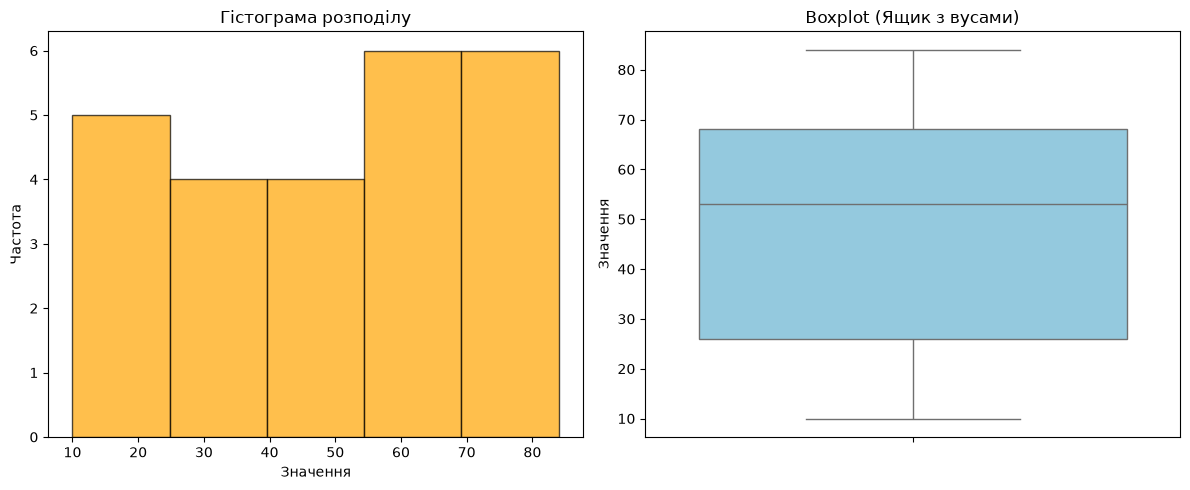

In [10]:
data_4 = np.random.randint(10, 90, size=25)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(data_4, bins=5, color='orange', edgecolor='black', alpha=0.7)
plt.title('Гістограма розподілу')
plt.xlabel('Значення')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
sns.boxplot(y=data_4, color='skyblue')
plt.title('Boxplot (Ящик з вусами)')
plt.ylabel('Значення')

plt.tight_layout()
plt.show()

### Завдання 5: Аналіз розподілу
Згенерувати випадкову вибірку випадкових величин, об'ємом 75 елементів (цілі числа). Перевірити, чи відповідає вибірка нормальному розподілу за допомогою тесту Шапіро-Вілка.

In [11]:
data_5 = np.random.randint(1, 100, size=75)
stat_shapiro, p_shapiro = stats.shapiro(data_5)

print(f"Статистика Шапіро-Вілка: {stat_shapiro}, Р-значення: {p_shapiro}")

alpha = 0.05
if p_shapiro > alpha:
    print("Пояснення: Дані відповідають нормальному розподілу.")
else:
    print("Пояснення: Дані НЕ відповідають нормальному розподілу (оскільки генерувалися за рівномірним законом).")

Статистика Шапіро-Вілка: 0.9419923268897483, Р-значення: 0.0018591969883171016
Пояснення: Дані НЕ відповідають нормальному розподілу (оскільки генерувалися за рівномірним законом).


### Завдання 6: Аналіз варіації (ANOVA)
Згенерувати три випадкові вибірки випадкових величин, об'ємом 20 елементів (цілі числа). Провести односторонній дисперсійний аналіз (ANOVA).

In [12]:
group_1 = np.random.randint(10, 30, size=20)
group_2 = np.random.randint(15, 35, size=20)
group_3 = np.random.randint(40, 60, size=20)

f_stat, p_val_anova = stats.f_oneway(group_1, group_2, group_3)

print(f"F-статистика: {f_stat}, Р-значення: {p_val_anova}")

alpha = 0.05
if p_val_anova < alpha:
    print("Пояснення: Нульова гіпотеза про рівність середніх відхиляється. Принаймні одна група має суттєву відмінність.")
else:
    print("Пояснення: Середні значення між групами суттєво не відрізняються.")

F-статистика: 126.56964297160442, Р-значення: 1.079108420190185e-21
Пояснення: Нульова гіпотеза про рівність середніх відхиляється. Принаймні одна група має суттєву відмінність.
